# MercaRAG — Experimento de chunking
Compara las tres estrategias de la Entrega 1 con los **mismos documentos y las mismas preguntas**.

| Estrategia | Sugerido por el curso | Parámetros del grupo | Herramienta |
|---|---|---|---|
| Fixed-size | 256 tokens, overlap 32 | **512 tokens, overlap 64** | LangChain `TokenTextSplitter` |
| Sentence-aware | máximo 5 oraciones | **6 oraciones, overlap 1** | spaCy `es_core_news_sm` |
| Semantic | umbral coseno 0,75–0,85 | **umbral 0,60–0,70** | Sentence Transformers (MiniLM) |

**Hipótesis (Entrega 1):** el chunking semántico funcionará mejor porque corta en los quiebres de significado y no en tamaños fijos.

Requisito: haber ejecutado `01_rag_multimodal_mercarag.ipynb` (o al menos sus secciones 1–8) para que los chunks estén en la base.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mercarag import config, db, documentos, chunking, carga, evaluacion
from mercarag.embeddings import Modelos

conn = db.get_connection()
modelos = Modelos()
docs = documentos.cargar_documentos()
print(f"{len(docs)} documentos | {len(evaluacion.PREGUNTAS_PRUEBA)} preguntas de prueba")

93 documentos | 27 preguntas de prueba


## 1. ¿Dónde corta el chunking semántico?
Cada oración se compara (coseno) con el **centroide** del chunk que se viene armando. Si la similitud cae por debajo del umbral,
la oración abre un chunk nuevo. Además, si el chunk superaría lo que MiniLM puede leer (`max_tokens`), también se corta.
Las cruces marcan los cortes con cada umbral.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

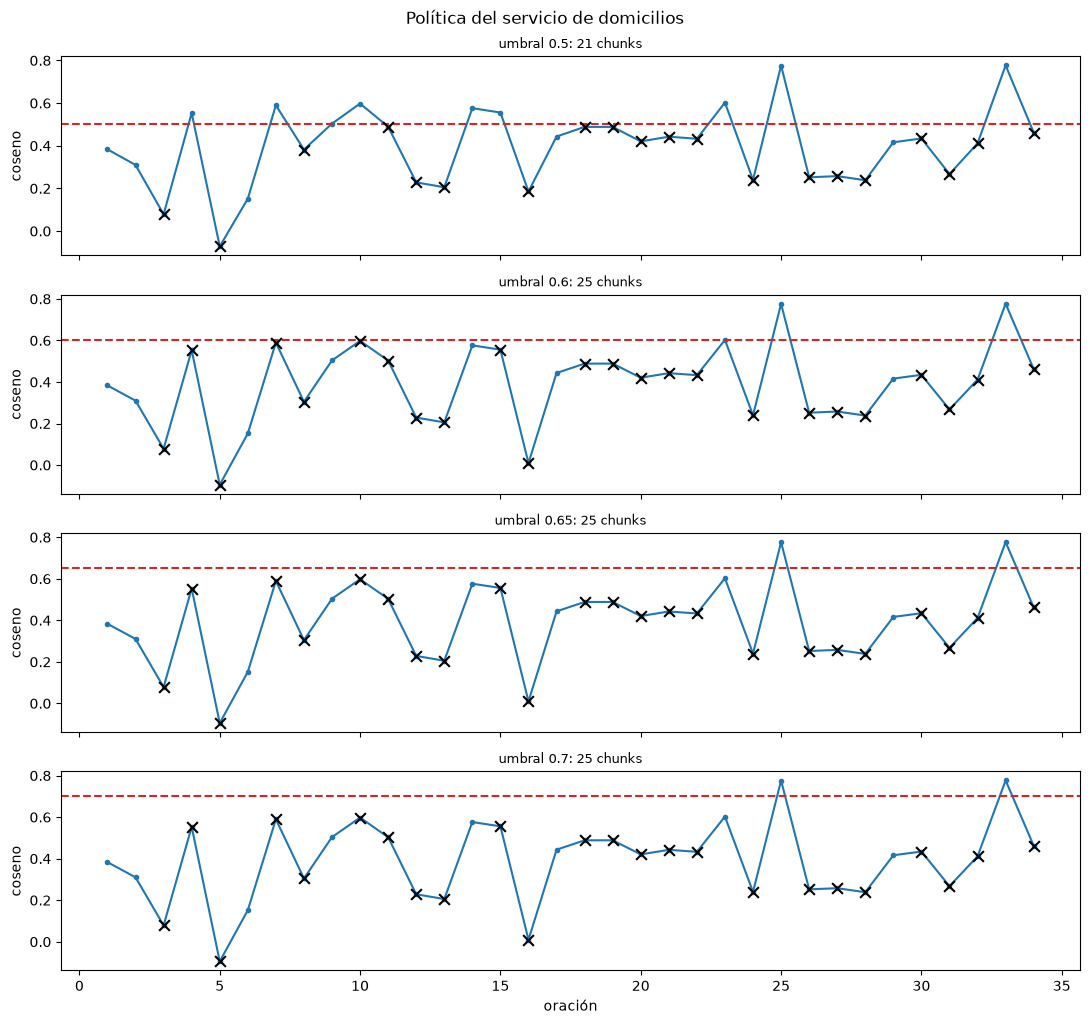

corte antes de la oración 3 (sim 0.08): Cada pedido se despacha desde el punto de venta más cercano a la dirección de entrega que 
corte antes de la oración 4 (sim 0.55): Si ninguna sede tiene el pedido completo, el sistema divide el pedido o le propone al clie
corte antes de la oración 5 (sim -0.09): Horarios.
corte antes de la oración 7 (sim 0.59): Los domingos y festivos el último pedido se recibe a las 6:00 p. m.
corte antes de la oración 8 (sim 0.30): Costos y pedido mínimo.
corte antes de la oración 10 (sim 0.60): El domicilio cuesta 4.500 pesos para pedidos entre 30.000 y 99.999 pesos, y es gratis para
corte antes de la oración 11 (sim 0.50): Para Villamaría y los barrios de la periferia, como La Enea alta y Bosques del Norte, se c
corte antes de la oración 12 (sim 0.23): Los clientes que compran más de cuatro veces al mes acceden al plan de domicilio gratis si
corte antes de la oración 13 (sim 0.21): Tiempos de entrega.
corte antes de la oración 15 (sim 0.56): En días de lluvia

In [2]:
doc = next(d for d in docs if d["codigo_doc"] == "POL_DOMICILIOS")
umbrales = [0.50, 0.60, 0.65, 0.70]   # dos de referencia y los de la Entrega 1
fig, ejes = plt.subplots(len(umbrales), 1, figsize=(11, 2.6 * len(umbrales)), sharex=True)
for eje, th in zip(np.atleast_1d(ejes), umbrales):
    oraciones, sims, cortes = evaluacion.similitudes_consecutivas(doc, modelos, threshold=th)
    x = np.arange(1, len(oraciones))
    eje.plot(x, sims, marker="o", ms=3)
    eje.axhline(th, ls="--", color="tab:red")
    c = [i for i in cortes if i > 0]
    eje.scatter(c, sims[np.array(c) - 1] if c else [], marker="x", s=60, color="black", zorder=3)
    eje.set_ylabel("coseno"); eje.set_title(f"umbral {th}: {len(cortes)} chunks", fontsize=9)
ejes[-1].set_xlabel("oración"); fig.suptitle(doc["titulo"]); plt.tight_layout(); plt.show()

oraciones, sims, cortes = evaluacion.similitudes_consecutivas(doc, modelos)
for i in cortes[1:]:
    print(f"corte antes de la oración {i} (sim {sims[i-1]:.2f}): {oraciones[i][:90]}")

## 2. Elegir el umbral semántico
Se prueba cada umbral **en memoria** (NumPy, sin tocar la base) y se mide la recuperación con las preguntas de prueba.
Los umbrales 0,60–0,70 son los de la Entrega 1 (`rango_entrega1 = True`); 0,40–0,55 son de referencia, porque la Entrega 1
define ese rango como experimental, "para después acomodarlo según resultados". Si el mejor queda fuera del rango, justifíquelo con esta tabla.
Revise también `oraciones_por_chunk`: con 1,0 el semántico se vuelve "una oración por chunk".

In [3]:
exp_umbral = evaluacion.experimento_umbral_semantico(docs, modelos, k=5)
exp_umbral

Batches:   0%|          | 0/24 [00:00<?, ?it/s]

umbral 0.40: 768 chunks en 20.7 s
umbral 0.45: 847 chunks en 6.0 s
umbral 0.50: 893 chunks en 4.2 s
umbral 0.55: 939 chunks en 3.2 s
umbral 0.60: 977 chunks en 2.0 s
umbral 0.65: 997 chunks en 1.0 s
umbral 0.70: 1001 chunks en 0.3 s


,threshold,rango_entrega1,chunks,oraciones_por_chunk,tokens_promedio,tokens_max,pct_truncados,hit@1,hit@5,MRR@5
0,0.40,False,768,1.87,49.0,239,0.0,0.593,0.815,0.698
1,0.45,False,847,1.70,45.6,197,0.0,0.704,0.889,0.784
2,0.50,False,893,1.61,43.8,197,0.0,0.704,0.889,0.790
3,0.55,False,939,1.53,42.3,107,0.0,0.741,0.889,0.815
4,0.60,True,977,1.47,41.1,94,0.0,0.778,0.889,0.833
5,0.65,True,997,1.44,40.6,94,0.0,0.778,0.889,0.827
6,0.70,True,1001,1.44,40.4,94,0.0,0.778,0.889,0.827


In [4]:
mejor = exp_umbral.sort_values(["MRR@5", "hit@1", "pct_truncados"], ascending=[False, False, True]).iloc[0]
UMBRAL_ELEGIDO = float(mejor["threshold"])
print(f"Umbral elegido: {UMBRAL_ELEGIDO}  (MRR@5 = {mejor['MRR@5']}, {int(mejor['chunks'])} chunks)")

# Se recarga SOLO la estrategia semántica con el umbral elegido (las otras dos no se tocan)
print(carga.cargar_documentos(conn, docs, modelos, estrategias=["semantico"],
                              params={"semantico": {"threshold": UMBRAL_ELEGIDO}}))

Umbral elegido: 0.6  (MRR@5 = 0.833, 977 chunks)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Batches:   0%|          | 0/31 [00:00<?, ?it/s]

{'documentos': 93, 'chunks': 977, 'por_estrategia': {'semantico': 977}, 'segundos': 39.27}


## 3. Tamaño de los chunks y conservación del contexto
`pct_truncados`: porcentaje de chunks con más tokens de los que MiniLM lee (`MAX_SEQ_TEXTO`). Lo que pasa de ese límite
**no entra en el vector**: es contexto perdido. Este es el análisis que pide la Entrega 1 para aprobar los 512 tokens del chunking fijo.

In [5]:
stats = evaluacion.estadisticas_chunks(conn)
print(f"Límite de MiniLM: {config.MAX_SEQ_TEXTO} tokens")
stats

Límite de MiniLM: 512 tokens


,estrategia,chunks,documentos,chars_promedio,tokens_promedio,tokens_max,pct_truncados
0,fijo,104,93,1094,287,477,0.0
1,oraciones,305,93,407,115,228,0.0
2,semantico,977,93,112,41,94,0.0


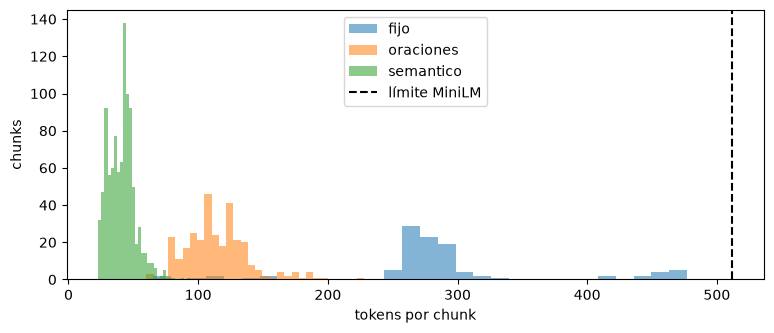

In [6]:
tokens = pd.DataFrame(db.consultar(conn, "SELECT estrategia_chunking AS estrategia, n_tokens FROM embeddings_texto", vectorial=False))
fig, eje = plt.subplots(figsize=(9, 3.5))
for estrategia in config.ESTRATEGIAS:
    eje.hist(tokens.loc[tokens.estrategia == estrategia, "n_tokens"], bins=30, alpha=0.55, label=estrategia)
eje.axvline(config.MAX_SEQ_TEXTO, color="black", ls="--", label="límite MiniLM")
eje.set_xlabel("tokens por chunk"); eje.set_ylabel("chunks"); eje.legend(); plt.show()

## 4. Recuperación por estrategia (en PostgreSQL)
Cada pregunta se busca con cada estrategia. Las consultas quedan registradas en `consulta` / `resultado` (RF-08).

In [7]:
detalle, resumen = evaluacion.evaluar_estrategias(conn, modelos, k=5, guardar=True)
resumen

,hit@1,hit@5,MRR@5,latencia_ms,score_top1
estrategia,,,,,
fijo,0.407,0.556,0.481,1.8,0.439
oraciones,0.630,0.852,0.722,1.8,0.636
semantico,0.778,0.889,0.833,3.4,0.701


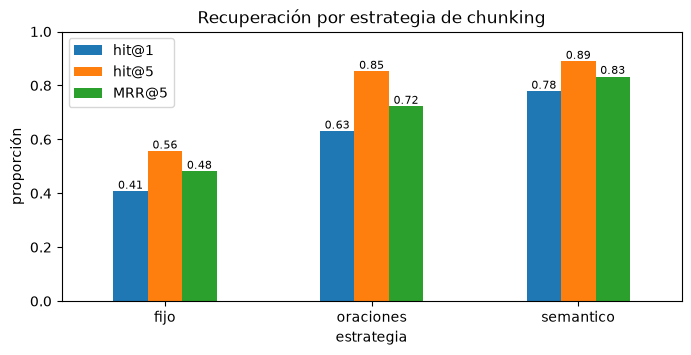

In [8]:
ax = resumen[["hit@1", "hit@5", "MRR@5"]].plot.bar(figsize=(8, 3.5), rot=0, ylim=(0, 1))
ax.set_title("Recuperación por estrategia de chunking"); ax.set_ylabel("proporción")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.show()

Preguntas en las que alguna estrategia falla (el documento correcto no está en el top 5 o no es el primero):

In [9]:
pivot = detalle.pivot_table(index=["pregunta", "esperado"], columns="estrategia", values="posicion", aggfunc="first")
pivot[pivot.isna().any(axis=1) | (pivot != 1).any(axis=1)]

,estrategia,fijo,oraciones,semantico
pregunta,esperado,,,
"Pagué con tarjeta de crédito, ¿cuánto tarda el reembolso?",POL_DEVOLUCIONES,2.0,1.0,1.0
fruta ácida de cáscara naranja para hacer jugo,FICHA_LULO,NaN,1.0,2.0
pan redondo hecho con almidón de yuca y queso,FICHA_PAN_DE_BONO,NaN,2.0,1.0
¿Cuál es la dirección del supermercado en Chipre?,GUIA_PUNTOS_VENTA,2.0,NaN,1.0
¿Cuánto cuesta el domicilio si mi pedido es de 50.000 pesos?,POL_DOMICILIOS,NaN,1.0,1.0
¿Cuánto tiempo guardan mis datos de facturación?,POL_DATOS_PERSONALES,1.0,1.0,2.0
¿Cuántos días tengo para devolver un detergente?,POL_DEVOLUCIONES,1.0,4.0,NaN
¿Cómo se conserva la pechuga de pollo?,FICHA_PECHUGA_DE_POLLO,NaN,1.0,2.0
¿Cómo se prepara la aguapanela con queso?,GUIA_RECETAS,NaN,1.0,1.0


## 5. Guardar resultados

In [10]:
config.RESULTADOS_DIR.mkdir(parents=True, exist_ok=True)
exp_umbral.to_csv(config.RESULTADOS_DIR / "experimento_umbral_semantico.csv", index=False)
stats.to_csv(config.RESULTADOS_DIR / "estadisticas_chunks.csv", index=False)
detalle.to_csv(config.RESULTADOS_DIR / "evaluacion_detalle.csv", index=False)
resumen.to_csv(config.RESULTADOS_DIR / "evaluacion_resumen.csv")
print("Guardado en", config.RESULTADOS_DIR)

Guardado en /home/estudiante/trabajo/data/resultados


## 6. Conclusión (completar con los resultados)
- **Mejor estrategia por MRR@5:** …
- **¿Se cumplió la hipótesis del chunking semántico?** …
- **¿Los 512 tokens del chunking fijo conservan el contexto?** (ver `pct_truncados`) …
- **Umbral semántico elegido y por qué:** …
- **Latencia:** todas las búsquedas deben estar por debajo de 1 s (requerimiento no funcional).

In [11]:
conn.close()